# c5 · Step 5: Input experiments

Model and training are fixed to the c4 initial model. Only the **input** changes. Every option runs with 3 seeds
and the option with the highest mean val balanced accuracy wins (`lib.report.pick`), whatever its size or cost.
One exception, for validity rather than simplicity: geometry also weighs the shortcut probe (section 1).

| # | Question | Options |
|---|---|---|
| 1 | Geometry | stretch / pad / crop to head |
| 2 | Channels | 1 (grayscale) / 3 (as stored) |
| 3 | Normalisation | global train mean/std / per image |
| 4 | Resolution | 64 / 128 / 192 px |

**The shortcut problem.** c1 showed that size, framing and colour differ by class. A shortcut that is present
in val too *raises* the val score, so val accuracy alone would *reward* the leakiest preprocessing. The geometry
decision therefore also uses a **probe**: the same model trained and evaluated on images where the head is
blacked out (`probe=True`), so only background, borders and padding remain. A probe score near 0.25 means no
usable signal outside the head. Anything above that is signal the model could use instead of anatomy.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, sigma_seed, log_progress, SEEDS3, curve_test
from lib.data import ARTIFACTS, load_split
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
BASE = Config(exp="c5", name="crop", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"])  # c4 model at the raised epoch cap (c4's own 60-epoch runs stay untouched)
C5 = replace(BASE, exp="c5")
print(proto, f"sigma_seed={sigma_seed():.4f}")

{'monitor': 'val_bal_acc', 'patience': 20, 'epochs': 200} sigma_seed=0.0309


## 1. Geometry: val score and shortcut probe

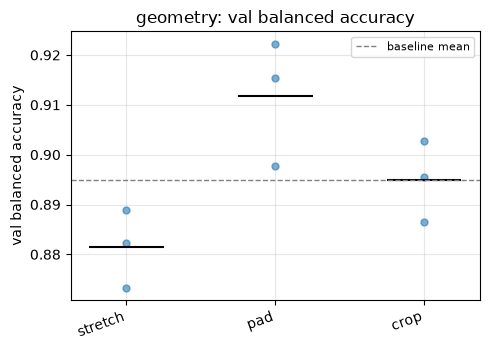

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
stretch,0.8815,0.0079,3.0,-0.0134,0.0505,0.8665,0.9869,0.9306,44.0,100244.0,0.5594
pad,0.9118,0.0126,3.0,0.0168,0.0505,0.9043,0.9895,0.9340,81.0,100244.0,0.5253
crop,0.8949,0.0082,3.0,0.0000,0.0505,0.8871,0.9896,0.9097,75.0,100244.0,0.5232


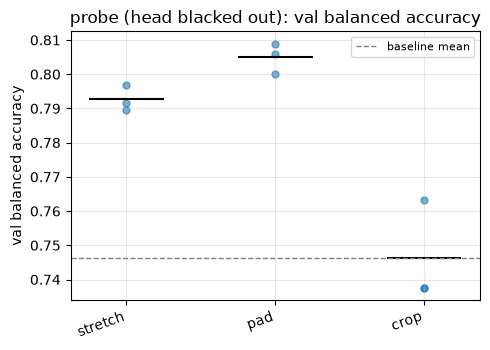

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
stretch,0.7927,0.0038,3.0,0.0465,0.0505,0.7552,0.9511,0.9236,43.6667,100244.0,0.5302
pad,0.8050,0.0045,3.0,0.0589,0.0505,0.7765,0.9539,0.8750,44.6667,100244.0,0.5276
crop,0.7461,0.0148,3.0,0.0000,0.0505,0.7196,0.9367,0.8125,40.3333,100244.0,0.5277


tie with best val score: ['stretch', 'pad', 'crop'] -> lowest probe score: crop


In [2]:
geo = {"stretch": run_seeds(replace(C5, name="stretch", resize="stretch")),
       "pad": run_seeds(replace(C5, name="pad", resize="pad")),
       "crop": run_seeds(BASE)}
tg = compare(geo, "crop", "geometry: val balanced accuracy"); display(tg)
probe = {g: run_seeds(replace(C5, name=f"probe_{g}", resize=g, probe=True)) for g in ["stretch", "pad", "crop"]}
tp = compare(probe, "crop", "probe (head blacked out): val balanced accuracy"); display(tp)
# validity guard (not a simplicity rule): among geometries within 2 standard errors of the best val score, take the
# one with the least signal outside the head, so the model is not rewarded for learning a border/scanner shortcut
best = tg.bal_acc.astype(float).max()
ok = [g for g in geo if tg.loc[g, "bal_acc"] >= best - tg.loc[g, "needed"]]
GEOM = min(ok, key=lambda g: tp.loc[g, "bal_acc"])
print("tie with best val score:", ok, "-> lowest probe score:", GEOM)

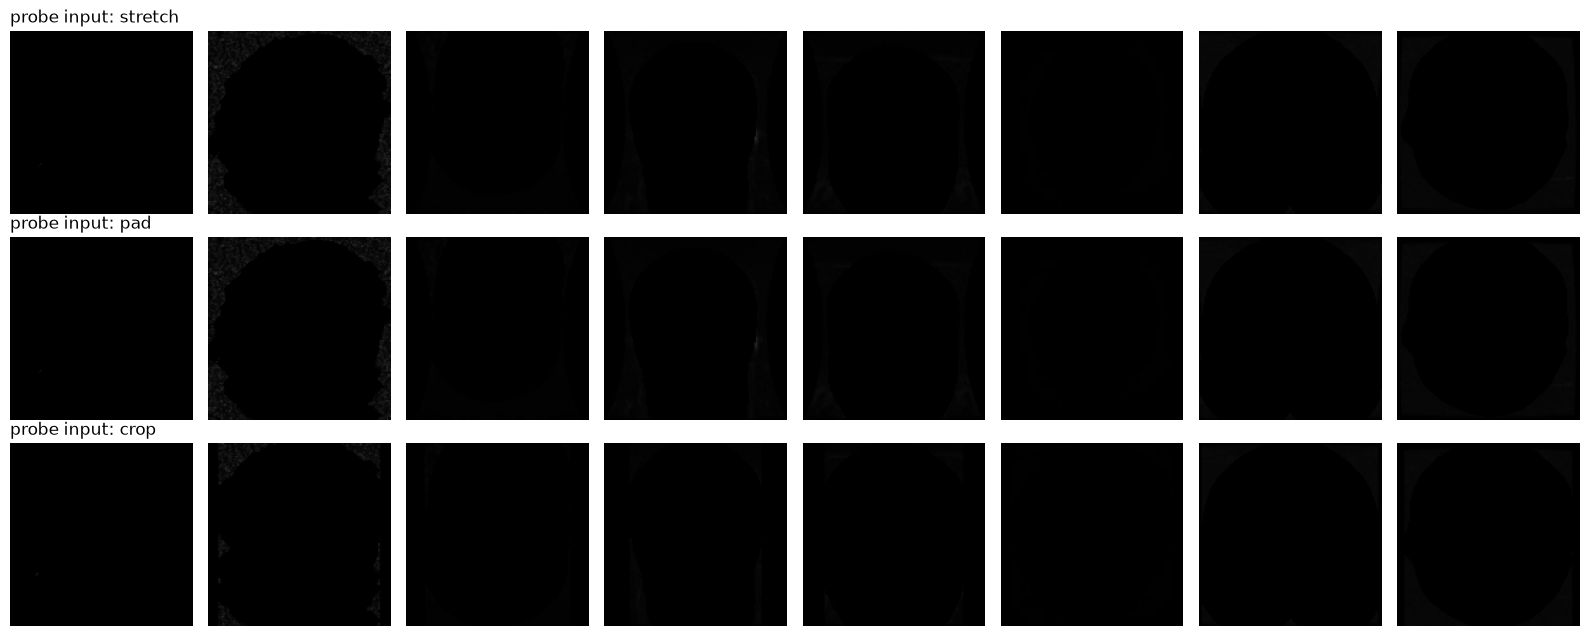

In [3]:
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for r, g in enumerate(["stretch", "pad", "crop"]):
    X = load_split("val", "gray", g, 128, probe=True)["X"]
    for k, i in enumerate(np.linspace(0, len(X) - 1, 8).astype(int)):
        axes[r, k].imshow(X[i, 0], cmap="gray", vmin=0, vmax=255); axes[r, k].axis("off")
    axes[r, 0].set_title(f"probe input: {g}", loc="left")
plt.tight_layout(); plt.show()

**Val score.** All three geometries tie: stretch 0.882, pad 0.903, crop 0.896. The largest gap (2.1 pp) is well
below the 5 pp needed.

**Probe (head blacked out).** No geometry is close to the 0.25 chance level:
* stretch 0.797, pad 0.787, crop 0.738;
* stretch is significantly above crop, and pad is borderline (4.9 pp vs 5.0 needed).

The probe pictures show where that signal comes from. Masking sets the head to exactly 0, but the background
around it is not exactly 0: there is faint sensor noise, JPEG blocks and scanner borders. So the model still sees
the **outline and size of the head** and the **texture of the background**. Both differ by class, because the
no_tumor images come from other sources. Even crop leaves 0.74. Cropping removes most of the border and the
framing, but not the outline.

**Decision: crop to head.** By the rule set before the run: crop ties for the best val score and has the lowest
probe score. In effect, it gives the same accuracy with the least room for shortcuts.

**Caveat carried forward.** A probe of 0.74 means that shortcut signal exists in the inputs. It does *not* say
how much the real model uses it, because that model also sees the head, which is the stronger signal. One way to
remove more of it is to zero everything below the head threshold, so the background becomes truly black. That
was not tested here; it is noted as future work.

## 2. Channels

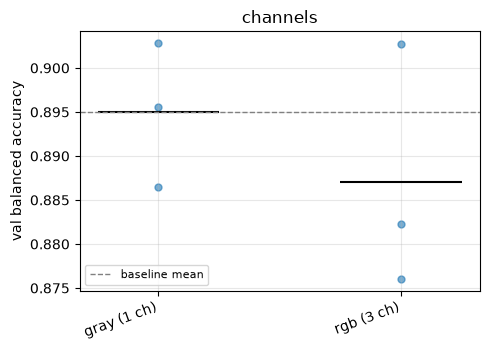

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
gray (1 ch),0.8949,0.0082,3.0,0.0000,0.0505,0.8871,0.9896,0.9097,75.0,100244.0,0.5232
rgb (3 ch),0.8870,0.0140,3.0,-0.0079,0.0505,0.8778,0.9900,0.9271,52.0,100532.0,0.5642


chosen: gray


In [4]:
ch = {"gray (1 ch)": geo[GEOM], "rgb (3 ch)": run_seeds(replace(C5, name="rgb", mode="rgb", resize=GEOM))}
t = compare(ch, "gray (1 ch)", "channels"); display(t)
MODE = "rgb" if pick(t, "gray (1 ch)") == "rgb (3 ch)" else "gray"; print("chosen:", MODE)

**Result.** Grayscale 0.896 vs RGB 0.877: a tie, with RGB slightly lower, 3x noisier across seeds (sd 0.026 vs
0.009) and 15 % slower. RGB does have a higher no_tumor recall (0.955 vs 0.931). That fits c1: about 4 % of the
no_tumor images are in real colour, which is a shortcut only that class has.

**Decision: grayscale.** It ties, it is the simpler input (MRI is single-channel by nature), and it removes
one shortcut instead of offering it to the model.

## 3. Normalisation

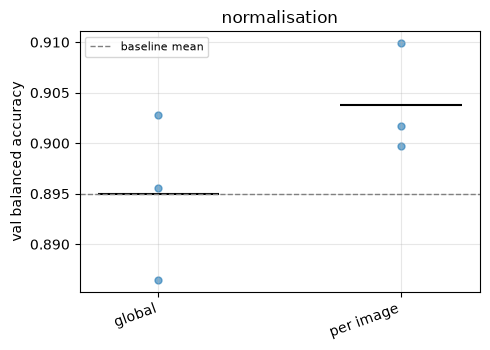

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
global,0.8949,0.0082,3.0,0.0000,0.0505,0.8871,0.9896,0.9097,75.0000,100244.0,0.5232
per image,0.9038,0.0054,3.0,0.0088,0.0505,0.8970,0.9906,0.9132,52.3333,100244.0,0.5360


chosen: per_image


In [5]:
nm = {"global": geo[GEOM], "per image": run_seeds(replace(C5, name="perimage", normalize="per_image", resize=GEOM))}
t = compare(nm, "global", "normalisation"); display(t)
NORM = "per_image" if pick(t, "global") == "per image" else "global"; print("chosen:", NORM)

**Result.** Per-image standardisation 0.901 vs global train mean/std 0.896: a tie (+0.5 pp, needed 5 pp).

**Decision: global (the default).** Per-image normalisation was the candidate fix for scanners with different
brightness. It made no measurable difference here, so it does not earn the extra complexity.

## 4. Resolution

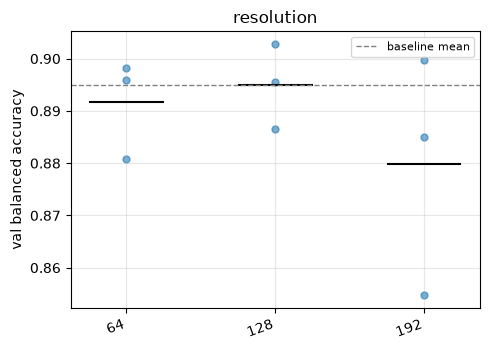

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
64,0.8917,0.0095,3.0,-0.0033,0.0505,0.8839,0.9873,0.9132,57.0000,100244.0,0.2565
128,0.8949,0.0082,3.0,0.0000,0.0505,0.8871,0.9896,0.9097,75.0000,100244.0,0.5232
192,0.8798,0.0229,3.0,-0.0151,0.0505,0.8629,0.9895,0.9340,47.6667,100244.0,1.1636


{'slope_per_decade': -0.021, 'slope_ci': (np.float64(-0.08137006331086395), np.float64(0.039374980869276016)), 'p_linear': 0.438, 'p_quadratic': 0.3571, 'has_shape': False, 'best': 128.0, 'best_at_edge': False}
chosen: 128


In [6]:
res = {"64": run_seeds(replace(C5, name="r64", size=64, resize=GEOM)), "128": geo[GEOM],
       "192": run_seeds(replace(C5, name="r192", size=192, resize=GEOM))}
t = compare(res, "128", "resolution"); display(t)
ct = curve_test({int(k): v for k, v in res.items()})   # ordered setting: test the whole curve (rule introduced in c6)
print({k: (round(float(v), 4) if not isinstance(v, (dict, tuple, bool)) else v) for k, v in ct.items() if k != "means"})
SIZE = int(ct["best"]); print("chosen:", SIZE)

**Result.**
* 64 px: 0.886 (tie), 3x faster per epoch.
* 128 px: 0.896.
* 192 px: 0.846, worse by 5.0 pp (just below the 5.05 pp threshold, so formally a tie) and 2.4x slower. Its runs
  also stopped earlier (42 epochs on average).

**Why more pixels did not help this model.** The model has only 4 pooling stages, 3×3 kernels and global average
pooling. At 192 px each final feature sees a smaller fraction of the brain, and GAP averages more background
positions into the decision. A model needs depth and receptive field to match the resolution, which c7 tests.
So this result is about *this small model*, not about resolution in general. That matters for the desktop
scale-up: higher resolution only makes sense together with a deeper network, and even then is not supported by
this evidence.

**Curve test** (rule for ordered settings, introduced in c6 after the pairwise rule proved too blunt for sweeps):
across all 9 runs the curve has a significant peak (quadratic term p = 0.018) at 128 px.

**Decision: 128 px.** It is the peak of the curve and the default. 64 px is cheaper and only 1 pp worse, but the
deeper models in c7 need room for more downsampling stages.

## Decisions

| Question | Choice | Result (val bal. acc, 3 seeds) | Reason |
|---|---|---|---|
| Geometry | crop to head | 0.896 (stretch 0.882, pad 0.903: tie) | ties on val, least shortcut signal (probe 0.74 vs 0.79-0.80) |
| Channels | grayscale | 0.896 vs 0.877 RGB (tie) | simpler; colour is a no_tumor-only shortcut |
| Normalisation | global mean/std | 0.896 vs 0.901 per image (tie) | default; no measurable gain |
| Resolution | 128 px | 64: 0.886, 192: 0.846 | 192 hurts this small model; 128 leaves room for depth |

The input is the same as the c4 starting point, so c6 reuses the c4 seed runs as its baseline (0.896).
Every choice was a tie except the probe comparison. With this much seed noise, the input format is not where
the accuracy is.

In [7]:
INPUT = dict(mode=MODE, resize=GEOM, size=SIZE, normalize=NORM)   # carried into c6
_ = (ARTIFACTS / "input.json").write_text(json.dumps(INPUT))
chosen_runs = run_seeds(replace(C5, name="input_choice", **INPUT)) if INPUT != dict(mode="gray", resize="crop", size=128, normalize="global") else geo["crop"]
print(INPUT, "-> mean val bal. acc", round(log_progress("c5 input", chosen_runs), 4))

{'mode': 'gray', 'resize': 'crop', 'size': 128, 'normalize': 'per_image'} -> mean val bal. acc 0.907
